In [9]:
from google.colab import files

uploaded = files.upload()

Saving playlist_2010to2023.csv to playlist_2010to2023.csv
Saving Billboard_Hot100_Songs_Spotify_1946-2022.csv to Billboard_Hot100_Songs_Spotify_1946-2022.csv


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

In [11]:
billboard = pd.read_csv(
    "Billboard_Hot100_Songs_Spotify_1946-2022.csv"
)

playlist = pd.read_csv(
    "playlist_2010to2023.csv",
    encoding="latin1"
)

print("Billboard dataset:", billboard.shape)
print("Playlist dataset:", playlist.shape)

Billboard dataset: (6879, 24)
Playlist dataset: (2400, 23)


In [13]:
print("BILLBOARD COLUMNS")
print(billboard.columns.tolist())

print("\nPLAYLIST COLUMNS")
print(playlist.columns.tolist())

billboard.head()
playlist.head()

BILLBOARD COLUMNS
['Song', 'Album', 'Album Release Date', 'Artist Names', 'Artist(s) Genres', 'Hot100 Ranking Year', 'Hot100 Rank', 'Song Length(ms)', 'Spotify Link', 'Song Image', 'Spotify URI', 'Popularity', 'Acousticness', 'Danceability', 'Energy', 'Instrumentalness', 'Liveness', 'Loudness', 'Speechiness', 'Tempo', 'Valence', 'Key', 'Mode', 'Time Signature']

PLAYLIST COLUMNS
['playlist_url', 'year', 'track_id', 'track_name', 'track_popularity', 'album', 'artist_id', 'artist_name', 'artist_genres', 'artist_popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature']


,playlist_url,year,track_id,track_name,track_popularity,album,artist_id,artist_name,artist_genres,artist_popularity,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,https://open.spotify.com/playlist/37i9dQZF1DWU...,2000,6naxalmIoLFWR0siv8dnQQ,Oops!...I Did It Again,81,Oops!... I Did It Again,26dSoYclwsYLMAKD3tpOr4,Britney Spears,"['dance pop', 'pop']",81,...,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,211160,4
1,https://open.spotify.com/playlist/37i9dQZF1DWU...,2000,2m1hi0nfMR9vdGC8UcrnwU,All The Small Things,83,Enema Of The State,6FBDaR13swtiWwGhX1WQsP,blink-182,"['alternative metal', 'modern rock', 'pop punk...",79,...,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,167067,4
2,https://open.spotify.com/playlist/37i9dQZF1DWU...,2000,3y4LxiYMgDl4RethdzpmNe,Breathe,66,Breathe,25NQNriVT2YbSW80ILRWJa,Faith Hill,"['contemporary country', 'country', 'country d...",62,...,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,250547,4
3,https://open.spotify.com/playlist/37i9dQZF1DWU...,2000,0v1XpBHnsbkCn7iJ9Ucr1l,It's My Life,81,Crush,58lV9VcRSjABbAbfWS6skp,Bon Jovi,"['glam metal', 'rock']",79,...,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,224493,4
4,https://open.spotify.com/playlist/37i9dQZF1DWU...,2000,62bOmKYxYg7dhrC6gH9vFn,Bye Bye Bye,75,No Strings Attached,6Ff53KvcvAj5U7Z1vojB5o,*NSYNC,"['boy band', 'dance pop', 'pop']",70,...,-4.843,0,0.0479,0.0310,0.001200,0.0821,0.861,172.638,200400,4


In [14]:
print("Billboard missing values:")
print(billboard.isnull().sum())

print("\nPlaylist missing values:")
print(playlist.isnull().sum())

Billboard missing values:
Song                   0
Album                  0
Album Release Date     0
Artist Names           0
Artist(s) Genres       0
Hot100 Ranking Year    0
Hot100 Rank            0
Song Length(ms)        0
Spotify Link           0
Song Image             0
Spotify URI            0
Popularity             0
Acousticness           0
Danceability           0
Energy                 0
Instrumentalness       0
Liveness               0
Loudness               0
Speechiness            0
Tempo                  0
Valence                0
Key                    0
Mode                   0
Time Signature         0
dtype: int64

Playlist missing values:
playlist_url         0
year                 0
track_id             0
track_name           0
track_popularity     0
album                0
artist_id            0
artist_name          0
artist_genres        0
artist_popularity    0
danceability         0
energy               0
key                  0
loudness             0
mode         

In [15]:
def clean_song_name(x):
    x = str(x).lower()
    x = x.strip()
    x = x.replace("'", "")
    x = x.replace('"', "")
    x = x.replace("-", " ")
    x = x.replace("(", "")
    x = x.replace(")", "")
    x = " ".join(x.split())
    return x

In [16]:
billboard["song_clean"] = billboard["Song"].apply(clean_song_name)

playlist["song_clean"] = playlist["track_name"].apply(clean_song_name)

In [17]:
billboard_songs = set(billboard["song_clean"])

playlist_non_hits = playlist[
    ~playlist["song_clean"].isin(billboard_songs)
].copy()

print("Original playlist songs:", len(playlist))
print("Songs after removing Billboard overlaps:", len(playlist_non_hits))

Original playlist songs: 2400
Songs after removing Billboard overlaps: 922


In [18]:
playlist_non_hits = playlist_non_hits[
    playlist_non_hits["year"] <= 2022
].copy()

print("Non-hit candidates:", len(playlist_non_hits))

Non-hit candidates: 834


In [19]:
billboard["hit"] = 1

In [20]:
playlist_non_hits["hit"] = 0

In [21]:
billboard_ml = billboard[
    [
        "Popularity",
        "Acousticness",
        "Danceability",
        "Energy",
        "Instrumentalness",
        "Liveness",
        "Loudness",
        "Speechiness",
        "Tempo",
        "Valence",
        "Key",
        "Mode",
        "Time Signature",
        "Song Length(ms)",
        "hit"
    ]
].copy()

In [22]:
playlist_ml = playlist_non_hits[
    [
        "track_popularity",
        "acousticness",
        "danceability",
        "energy",
        "instrumentalness",
        "liveness",
        "loudness",
        "speechiness",
        "tempo",
        "valence",
        "key",
        "mode",
        "time_signature",
        "duration_ms",
        "hit"
    ]
].copy()

In [23]:
playlist_ml.columns = billboard_ml.columns

print(billboard_ml.columns)
print(playlist_ml.columns)

Index(['Popularity', 'Acousticness', 'Danceability', 'Energy',
       'Instrumentalness', 'Liveness', 'Loudness', 'Speechiness', 'Tempo',
       'Valence', 'Key', 'Mode', 'Time Signature', 'Song Length(ms)', 'hit'],
      dtype='object')
Index(['Popularity', 'Acousticness', 'Danceability', 'Energy',
       'Instrumentalness', 'Liveness', 'Loudness', 'Speechiness', 'Tempo',
       'Valence', 'Key', 'Mode', 'Time Signature', 'Song Length(ms)', 'hit'],
      dtype='object')


In [24]:
final_df = pd.concat(
    [billboard_ml, playlist_ml],
    ignore_index=True
)

print("Final dataset shape:", final_df.shape)

Final dataset shape: (7713, 15)


In [25]:
print(final_df.isnull().sum())

final_df = final_df.dropna().reset_index(drop=True)

print("Final dataset after cleaning:", final_df.shape)

Popularity          0
Acousticness        0
Danceability        0
Energy              0
Instrumentalness    0
Liveness            0
Loudness            0
Speechiness         0
Tempo               0
Valence             0
Key                 0
Mode                0
Time Signature      0
Song Length(ms)     0
hit                 0
dtype: int64
Final dataset after cleaning: (7713, 15)


hit
1    6879
0     834
Name: count, dtype: int64


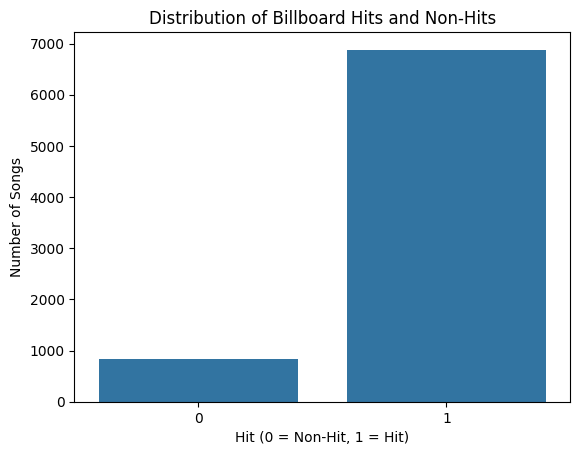

In [26]:
print(final_df["hit"].value_counts())

sns.countplot(x="hit", data=final_df)

plt.title("Distribution of Billboard Hits and Non-Hits")
plt.xlabel("Hit (0 = Non-Hit, 1 = Hit)")
plt.ylabel("Number of Songs")
plt.show()

In [27]:
final_df.describe()

,Popularity,Acousticness,Danceability,Energy,Instrumentalness,Liveness,Loudness,Speechiness,Tempo,Valence,Key,Mode,Time Signature,Song Length(ms),hit
count,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7713.000000,7.713000e+03,7713.000000
mean,55.697524,0.285397,0.621152,0.608359,0.043301,0.180743,-8.421487,0.074035,119.300495,0.588933,5.233891,0.692467,3.944250,2.240280e+05,0.891871
std,21.155751,0.287314,0.155538,0.205831,0.164658,0.149932,3.745964,0.080259,28.131118,0.243650,3.586043,0.461502,0.308092,6.225696e+04,0.310564
min,0.000000,0.000004,0.000000,0.012000,0.000000,0.012400,-37.841000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.180000e+04,0.000000
25%,45.000000,0.041100,0.526000,0.467000,0.000000,0.087700,-10.797000,0.032600,98.043000,0.395000,2.000000,0.000000,4.000000,1.830000e+05,1.000000
50%,60.000000,0.176000,0.637000,0.629000,0.000004,0.123000,-7.712000,0.042800,118.082000,0.607000,5.000000,1.000000,4.000000,2.197600e+05,1.000000
75%,71.000000,0.480000,0.731000,0.771000,0.000496,0.231000,-5.538000,0.072000,134.480000,0.796000,8.000000,1.000000,4.000000,2.556000e+05,1.000000
max,94.000000,0.995000,0.988000,0.999000,0.985000,0.995000,-0.276000,0.911000,232.473000,0.991000,11.000000,1.000000,5.000000,1.561133e+06,1.000000


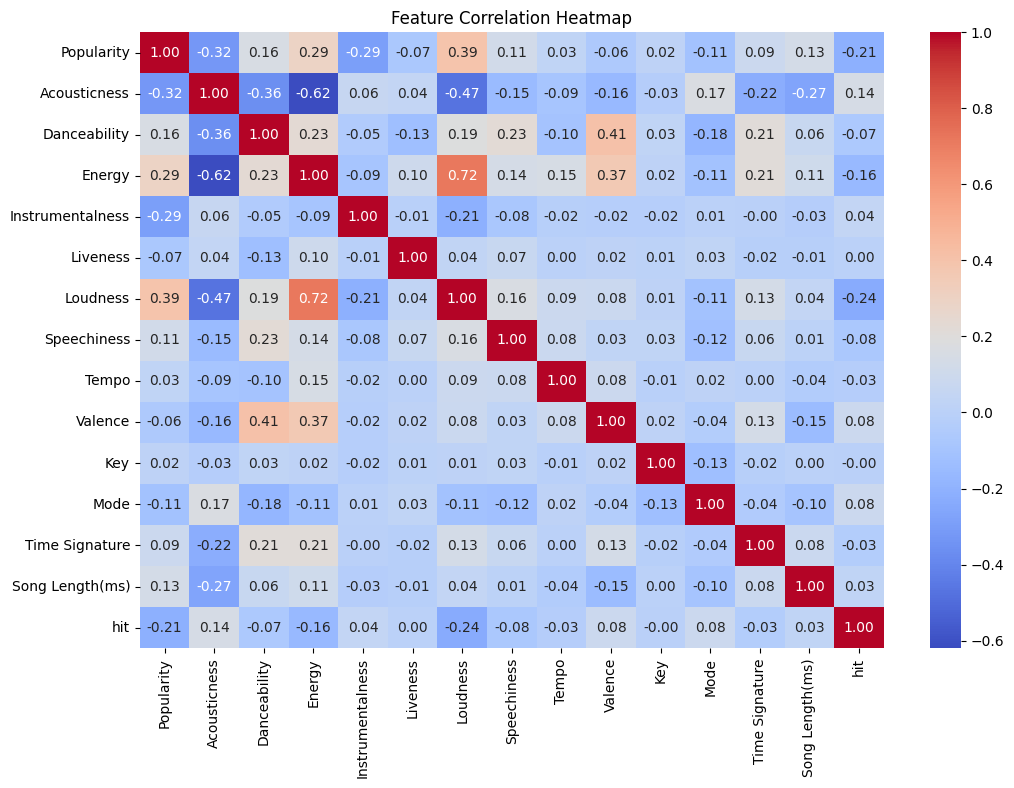

In [28]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    final_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [29]:
X = final_df.drop("hit", axis=1)
y = final_df["hit"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Popularity', 'Acousticness', 'Danceability', 'Energy', 'Instrumentalness', 'Liveness', 'Loudness', 'Speechiness', 'Tempo', 'Valence', 'Key', 'Mode', 'Time Signature', 'Song Length(ms)']

Target:
hit


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6170, 14)
Testing data: (1543, 14)


In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
# Model-1 Logistic Regression
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

Logistic Regression
----------------------
Accuracy : 0.8904731043421905
Precision: 0.8926480156148341
Recall   : 0.997093023255814
F1 Score : 0.9419842087195331

Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.01      0.02       167
           1       0.89      1.00      0.94      1376

    accuracy                           0.89      1543
   macro avg       0.61      0.50      0.48      1543
weighted avg       0.83      0.89      0.84      1543



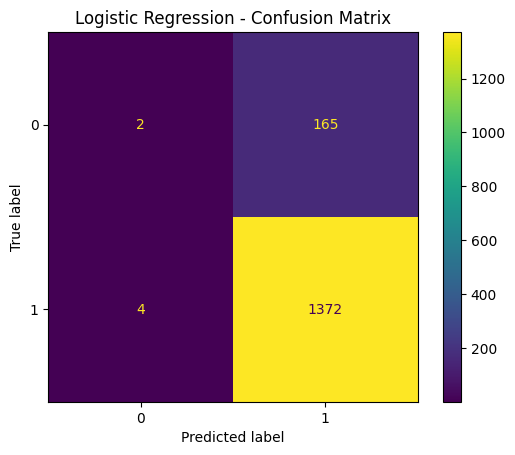

In [33]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

print("Logistic Regression")
print("----------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

#Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [34]:
# Model-2 Decision Tree
dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

Decision Tree
----------------------
Accuracy : 0.8885288399222294
Precision: 0.8929503916449086
Recall   : 0.9941860465116279
F1 Score : 0.9408528198074277

Classification Report:
              precision    recall  f1-score   support

           0       0.27      0.02      0.03       167
           1       0.89      0.99      0.94      1376

    accuracy                           0.89      1543
   macro avg       0.58      0.51      0.49      1543
weighted avg       0.83      0.89      0.84      1543



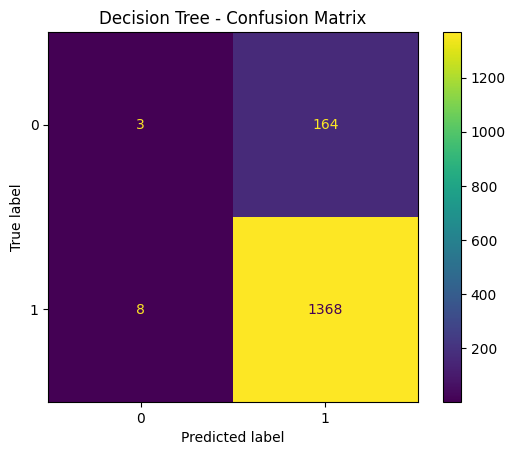

In [35]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)

print("Decision Tree")
print("----------------------")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

#Confusion Tree
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

Random Forest
----------------------
Accuracy : 0.8917692806221647
Precision: 0.8922777417261518
Recall   : 0.9992732558139535
F1 Score : 0.9427494000685636

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.01      0.01       167
           1       0.89      1.00      0.94      1376

    accuracy                           0.89      1543
   macro avg       0.70      0.50      0.48      1543
weighted avg       0.85      0.89      0.84      1543



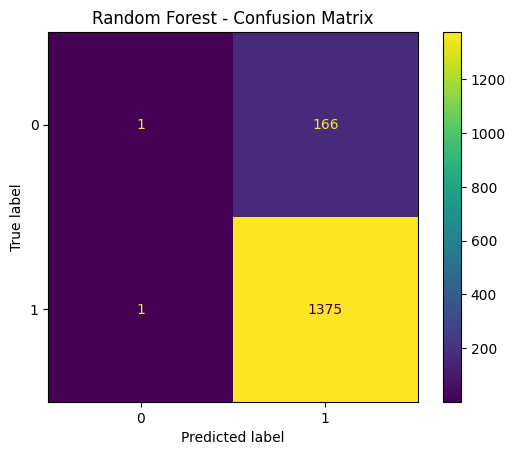

In [36]:
# Model 3- Random Forest

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("Random Forest")
print("----------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

#Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [37]:
#Model Comparison
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ],

    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision
    ],

    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall
    ],

    "F1 Score": [
        lr_f1,
        dt_f1,
        rf_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.890473,0.892648,0.997093,0.941984
1,Decision Tree,0.888529,0.892950,0.994186,0.940853
2,Random Forest,0.891769,0.892278,0.999273,0.942749


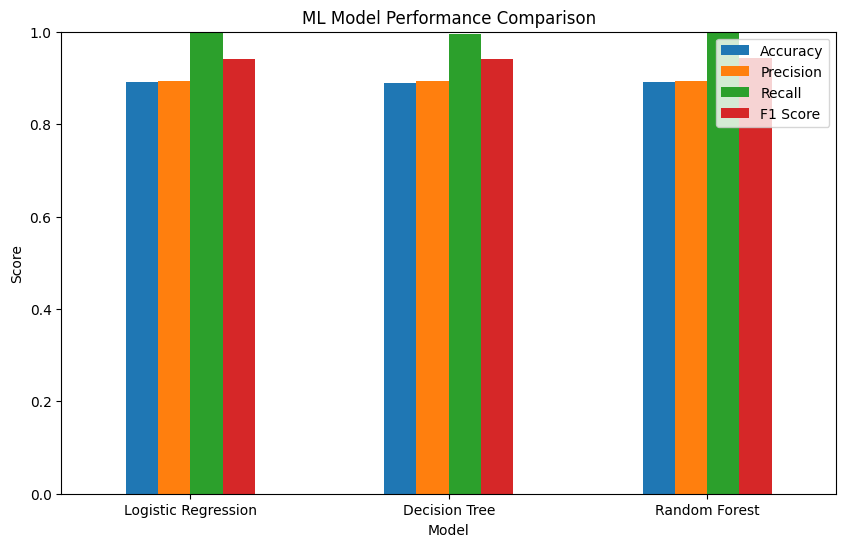

In [38]:
#Visual model comparison
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("ML Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [39]:
#Feature Importance
feature_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)

Loudness            0.146799
Popularity          0.137553
Valence             0.093534
Energy              0.089951
Song Length(ms)     0.086713
Acousticness        0.080102
Speechiness         0.073495
Tempo               0.067568
Danceability        0.067394
Liveness            0.060036
Instrumentalness    0.051499
Key                 0.032845
Mode                0.010266
Time Signature      0.002245
dtype: float64


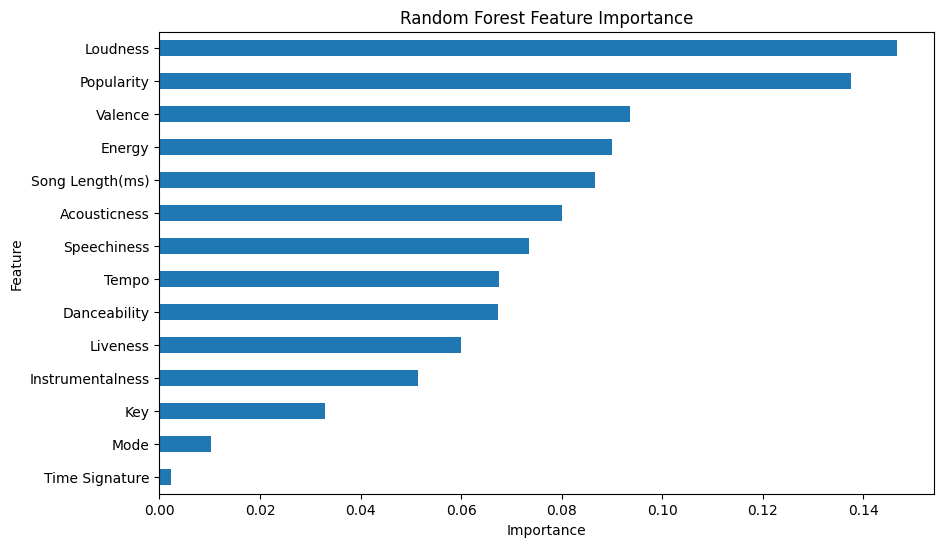

In [40]:
#Plot feature importance
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(
    kind="barh"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [41]:
#Final prediction
sample = X_test.iloc[[0]]

prediction = rf.predict(sample)[0]

if prediction == 1:
    print("Prediction: Billboard HIT")
else:
    print("Prediction: NOT a Billboard HIT")

Prediction: Billboard HIT


In [43]:
#Prediction probability
probability = rf.predict_proba(sample)[0]

print("Probability of Non-Hit:", probability[0])
print("Probability of Hit:", probability[1])

Probability of Non-Hit: 0.06891866899820172
Probability of Hit: 0.9310813310017986


In [44]:
#Final dataset
final_df.to_csv(
    "HitPredict_Final_Dataset.csv",
    index=False
)

print("Final dataset saved successfully.")

Final dataset saved successfully.


In [45]:
from google.colab import files

files.download("HitPredict_Final_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>